# The Simplex Method

**Seong Cho** · ACME Volume 2, Lab 13

**Lab objective:** implement a standard Simplex solver for the primal linear program, the straightforward algorithm for finding optimal solutions to optimization problems with linear constraints and cost functions, and use it on a product mix problem.

<sub>Lab specification from the *Volume 2* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

The solution code uses `np.row_stack()`, which NumPy 2.0 deprecated as an alias of `np.vstack()`. The code is kept as written, and the setup cell hides that one `DeprecationWarning` (IPython would otherwise print it after every cell that builds a tableau).

In [1]:
import warnings
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import linprog

warnings.filterwarnings("ignore", message="`row_stack` alias is deprecated", category=DeprecationWarning)

## Standard Form

Because of its simplicity and applicability, the Simplex Method has been named one of the most important algorithms invented within the last 100 years. It accepts a linear constrained optimization problem, also called a *linear program*, in the standard form

$$\begin{aligned} \text{maximize} \quad & \mathbf{c}^T\mathbf{x} \\ \text{subject to} \quad & A\mathbf{x} \preceq \mathbf{b} \\ & \mathbf{x} \succeq \mathbf{0}. \end{aligned}$$

Any linear program can be converted to standard form, so there is no loss of generality. The set of points satisfying the constraints is the *feasible region*. Because the constraints are linear, it forms a *polytope* with flat faces and edges, and if an optimal point exists, it is one of the vertices (the spec's Figure 14.1). The Simplex Algorithm jumps among the vertices, moving along the edges of the feasible region so that the objective function always increases after each move.

The program is longer than most lab exercises, so it is broken into small steps, each a method of a Python class. The running example is

$$\begin{aligned} \text{maximize} \quad & 3x_0 + 2x_1 \\ \text{subject to} \quad & x_0 - x_1 \le 2 \\ & 3x_0 + x_1 \le 5 \\ & 4x_0 + 3x_1 \le 7 \\ & x_0, x_1 \ge 0. \end{aligned}$$

Its feasible region, found by intersecting pairs of constraint lines and keeping the feasible intersections (the vertices):

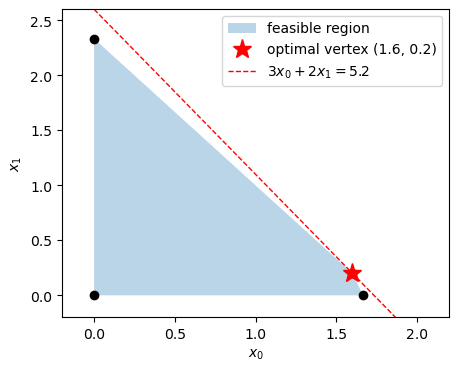

In [2]:
from itertools import combinations

c = np.array([3., 2])
A = np.array([[1., -1], [3, 1], [4, 3]])
b = np.array([2., 5, 7])

# All constraints as rows of Gx <= h, including x >= 0.
G = np.vstack((A, -np.eye(2)))
h = np.concatenate((b, np.zeros(2)))
verts = []
for i, j in combinations(range(len(G)), 2):
    if abs(np.linalg.det(G[[i,j]])) > 1e-12:
        v = np.linalg.solve(G[[i,j]], h[[i,j]])
        if np.all(G @ v <= h + 1e-12):
            verts.append(v)
verts = np.array(verts)
center = verts.mean(axis=0)
verts = verts[np.argsort(np.arctan2(*(verts - center).T[::-1]))]   # Order around the polygon.
best = verts[np.argmax(verts @ c)]

fig, ax = plt.subplots(figsize=(5, 4))
ax.fill(verts[:,0], verts[:,1], alpha=.3, label="feasible region")
ax.plot(verts[:,0], verts[:,1], 'ko')
ax.plot(*best, 'r*', ms=14, label=f"optimal vertex ({best[0]:.1f}, {best[1]:.1f})")
x0 = np.linspace(0, 2.2, 50)
ax.plot(x0, (c @ best - 3*x0)/2, 'r--', lw=1, label=r"$3x_0 + 2x_1 = 5.2$")
ax.set_xlim(-.2, 2.2); ax.set_ylim(-.2, 2.6)
ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$"); ax.legend()
plt.show()

## Accepting a Linear Program

The first task is to determine whether the Simplex algorithm can be used at all. Assuming that the problem is presented in standard form, check that the feasible region includes the origin.

## Problem 1: Feasibility at the origin

> **Problem 1.** Write a class that accepts the arrays $\mathbf{c}$, $A$, and $\mathbf{b}$ of a linear optimization problem in standard form. In the constructor, check that the system is feasible at the origin. That is, check that $A\mathbf{x} \preceq \mathbf{b}$ when $\mathbf{x} = \mathbf{0}$. Raise a `ValueError` if the problem is not feasible at the origin.
>
> (For now, we only check for feasibility at the origin. A more robust solver sets up the auxiliary problem and solves it to find a starting point if the origin is infeasible.)

The class below is my solution to Problems 1 to 6 together; the following sections show each part at work. Two changes were made to `pivot()` (see the comments marked "Fixed"): the index-list swap and the ratio test both gave wrong answers or errors once a problem needed more than a few pivots.

In [3]:
# Problems 1-6
class SimplexSolver(object):
    """Class for solving the standard linear optimization problem

                        maximize        c^Tx
                        subject to      Ax <= b
                                         x >= 0
    via the Simplex algorithm.
    """
    def __init__(self, c, A, b):
        """Check for feasibility and initialize the tableau.

        Parameters:
            c ((n,) ndarray): The coefficients of the objective function.
            A ((m,n) ndarray): The constraint coefficients matrix.
            b ((m,) ndarray): The constraint vector.

        Raises:
            ValueError: if the given system is infeasible at the origin.
        """
        # Save the dimensions for future use
        self.n = len(c)
        self.m = len(b)
        # Check if the origin is feasible
        x0 = np.zeros(self.n)
        if not (A@x0 <= b).all():
            raise ValueError("The problem is not feasible at the origin.")
        # Save each of the arrays
        self.c = c
        self.A = A
        self.b = b
        # Create an index list
        self.L = [self.n + i for i in range(self.m)] + \
                 [i for i in range(self.n)]

    def init_tableau(self):
        """Create an initial tableau using the given arrays.

        Returns:
            ((m+1,m+n+2) ndarray): The initial tableau.
        """
        # Exactly follow the form given in 14.1
        Im = np.eye(self.m)
        A_bar = np.column_stack((self.A,Im))
        c_bar = np.concatenate((self.c, np.zeros(self.m)))
        T1 = np.concatenate(([0], -c_bar, [1]))
        T2 = np.column_stack((self.b, A_bar, np.zeros(self.m)))
        return np.row_stack((T1, T2))

    def pivot(self, T):
        """Update the dictionary (tableau) using the pivoting mechanism.

        Parameters:
            ((m+1,m+n+2) ndarray): The tableau to be updated.

        Raises:
            ValueError: if the given system is unbounded
        """
        for i,t in enumerate(T[0][1:]): # Search through the entries of the first row
            if t < 0: # Stop when encountering the first negative value
                # Fixed: the ratios are now taken only over the rows with a positive
                # entry in the pivot column (other rows get -1 and are never chosen).
                # Testing R > 0 on all the ratios skipped degenerate rows (ratio 0) and
                # let a row with a zero entry (ratio inf) be chosen, which divided by
                # zero or missed an unbounded problem.
                pos = T[1:,i+1] > 0
                R = np.where(pos, T[1:, 0]/np.where(pos, T[1:,i+1], 1), -1) # Calculate the ratios
                # Raise a ValueError if there are no positive entries in the column
                if len(R[R>=0]) == 0:
                    raise ValueError("The problem is unbounded")
                # Find the row index, stopping at the first one found following Bland's rule
                p = np.min(R[R>=0])
                j = np.where(R==p)[0][0]
                break
        # Update the index list
        # Fixed: swap with the position of the entering index i in L. Position
        # self.m + i holds index i only until the first pivots; after that the swap
        # recorded the wrong basic variables, or raised an IndexError when a slack
        # variable re-entered the basis.
        k = self.L.index(i)
        self.L[j], self.L[k] = self.L[k], self.L[j]
        #Update the tableau
        T[j+1] /= T[j+1][i+1]
        for k in range(len(T)):
            if k != j+1:
                T[k] -= T[k,i+1]*T[j+1]

    def solve(self):
        """Solve the linear optimization problem.

        Returns:
            (float) The maximum value of the objective function.
            (dict): The basic variables and their values.
            (dict): The nonbasic variables and their values.
        """
        # Initialize our tableau
        table = self.init_tableau()
        obj = table[0]
        # Repeat until there are no negative value in the objective function
        while len(obj[obj<0]) != 0:
            # Update the tableau using the pivot function
            self.pivot(table)
            obj = table[0]
        # Find the optimum value, and the values for the basic and non basic variables
        optimum = table[0,0]
        basic = dict()
        nonbasic = dict()
        for i,v in enumerate(self.L[:self.m]):
            basic[v] = table[i+1,0]
        for v in self.L[self.m:]:
            nonbasic[v] = 0
        return optimum, basic, nonbasic

The running example is feasible at the origin; reversing the sign of $\mathbf{b}$ makes it infeasible there.

In [4]:
c = np.array([3., 2])
b = np.array([2., 5, 7])
A = np.array([[1., -1], [3, 1], [4, 3]])

S = SimplexSolver(c, A, b)          # Feasible at the origin: no error.
try:
    SimplexSolver(c, A, -b)
except ValueError as e:
    print("ValueError:", e)

ValueError: The problem is not feasible at the origin.


## Adding Slack Variables

The inequality constraints $A\mathbf{x} \preceq \mathbf{b}$ become equality constraints by introducing a *slack variable* for each constraint equation. If $A$ is $m \times n$, the $m$ slack variables form a vector $\mathbf{w}$ and the constraints become $A\mathbf{x} + \mathbf{w} = \mathbf{b}$. In the example, $\mathbf{w} = (x_2, x_3, x_4)^T$.

A convenient way to represent all the variables, primal and slack, is by subscript: the integers $0$ through $n-1$ refer to the original variables $x_0, \ldots, x_{n-1}$, and $n$ through $n+m-1$ to the slack variables (the slack variable for the $i$th row of the constraint matrix is index $n + i - 1$).

We also need to track which variables are *basic* (non-zero) and which are *nonbasic* (value 0). A Python list of integers, the *index list*, does this: there are $m$ basic variables, kept in the first $m$ locations, and the nonbasic variables are stored at the end. The ordering is important: if $i \le m$, the $i$th element of the list is the basic variable corresponding to the $i$th row of $A$.

Initially the basic variables are simply the slack variables, with values given by $\mathbf{b}$, so the example starts with the index list `L = [2, 3, 4, 0, 1]`. As the algorithm progresses, elements of the index list are swapped. For example, if index 4 becomes nonbasic while index 0 becomes basic:

In [5]:
L = [2, 3, 4, 0, 1]
L[2], L[3] = L[3], L[2]
L                           # The basic variables now have indices 2, 3, 0.

[2, 3, 0, 4, 1]

## Problem 2: Tracking the variables

> **Problem 2.** Design and implement a way to store and track all of the basic and non-basic variables.
>
> Hint: Using integers that represent the index of each variable is useful for Problem 4.

The constructor builds the index list `self.L` exactly as above, and `pivot()` swaps its entries.

In [6]:
S = SimplexSolver(c, A, b)
print(S.L)
assert S.L == [2, 3, 4, 0, 1]

[2, 3, 4, 0, 1]


## Creating a Tableau

The *tableau* (sometimes called the *dictionary*) is the data structure that tracks the state of the algorithm. One way to build it mimics the tableau used when performing the Simplex Algorithm by hand. Define $\bar{A} = \begin{bmatrix} A & I_m \end{bmatrix}$, where $I_m$ is the $m \times m$ identity, and $\bar{\mathbf{c}} \in \mathbb{R}^{n+m}$ whose first $n$ entries are $\mathbf{c}$ and final $m$ entries are zeros. Then the initial tableau is

$$T = \begin{bmatrix} 0 & -\bar{\mathbf{c}}^T & 1 \\ \mathbf{b} & \bar{A} & \mathbf{0} \end{bmatrix}. \tag{14.1}$$

The columns correspond to the variables (primal and slack) and the rows to the basic variables. With the index list convention (counting from 1),

$$\text{column } i \Leftrightarrow \text{index } i - 2, \quad i = 2, 3, \ldots, n+m+1, \qquad \text{row } j \Leftrightarrow L_{j-1}, \quad j = 2, 3, \ldots, m+1.$$

For the example, with $L = (2, 3, 4, 0, 1)$,

$$T = \begin{bmatrix} 0 & -3 & -2 & 0 & 0 & 0 & 1 \\ 2 & 1 & -1 & 1 & 0 & 0 & 0 \\ 5 & 3 & 1 & 0 & 1 & 0 & 0 \\ 7 & 4 & 3 & 0 & 0 & 1 & 0 \end{bmatrix}.$$

The third column corresponds to index 1, and the fourth row to index 4, since this is the third entry of the index list. This kind of tableau makes it easy to check progress by hand; the disadvantage is that pivot operations require careful bookkeeping to track the variables and constraints.

## Problem 3: The initial tableau

> **Problem 3.** Add a method to your Simplex solver that will create the initial tableau as a NumPy array.

`init_tableau()` builds (14.1):

In [7]:
T = S.init_tableau()
print(T)
T_spec = np.array([[0, -3, -2, 0, 0, 0, 1],
                   [2,  1, -1, 1, 0, 0, 0],
                   [5,  3,  1, 0, 1, 0, 0],
                   [7,  4,  3, 0, 0, 1, 0]])
assert np.array_equal(T, T_spec)

[[ 0. -3. -2. -0. -0. -0.  1.]
 [ 2.  1. -1.  1.  0.  0.  0.]
 [ 5.  3.  1.  0.  1.  0.  0.]
 [ 7.  4.  3.  0.  0.  1.  0.]]


## Pivoting

*Pivoting* swaps basic and nonbasic variables and transforms the tableau, moving from one vertex of the feasible polytope to another in a way that increases the objective function. First find the pivot element; its row and column give the variables to swap. Then row operations make the pivot column an elementary vector.

**Pivot column.** Search from left to right along the top row of the tableau (ignoring the first column) and stop at the first negative value. The corresponding index is the *entering index*: after the pivot it becomes a basic variable. In the example this is the second column, so the entering index is 0.

**Pivot row.** Select the pivot element from among the positive entries in the pivot column (ignoring the first row). If all entries in the pivot column are non-positive, the problem is unbounded and has no solution, and the algorithm should terminate. Otherwise, if the pivot column is column $j$ and its positive entries are $T_{i_1,j}, \ldots, T_{i_k,j}$, compute the ratios

$$\frac{T_{i_1,1}}{T_{i_1,j}}, \quad \frac{T_{i_2,1}}{T_{i_2,j}}, \quad \ldots, \quad \frac{T_{i_k,1}}{T_{i_k,j}}$$

and choose a pivot element that minimizes the ratio. If several entries tie, *Bland's Rule* says to choose the entry in the row corresponding to the smallest index (this prevents the algorithm from cycling back on itself infinitely). The index of the pivot row is the *leaving index*: it leaves the basis and becomes nonbasic. In the example the ratios are $2/1 = 2$, $5/3 = 1.66\ldots$, and $7/4 = 1.75$, so the pivot element is in the second column, third row, and the leaving index is $L_2 = 3$.

## Problem 4: Choosing the pivot

> **Problem 4.** Write a method that will determine the pivot row and pivot column according to Bland's Rule.

> **Definition 14.1 (Bland's Rule).** Choose the nonbasic variable with the smallest index that has a positive coefficient in the objective function as the leaving variable. Choose the basic variable with the smallest index among all the binding basic variables.
>
> Bland's Rule is important in avoiding cycles when performing pivots. This rule guarantees that a feasible Simplex problem will terminate in a finite number of pivots.

The pivot choice is the first half of `pivot()`. The entering index is the first negative entry of the top row, which is the smallest index since column $i+1$ holds index $i$; among tied ratios the first (topmost) row is taken. The next section checks the choice on the example.

## Completing the pivot

Next, swap the entering and leaving indices in the index list. In the example these are 0 and 3, so $L = (2, 0, 4, 3, 1)$ and the basic variables are now 2, 0, 4.

Finally, perform row operations: divide the pivot row by the pivot entry, then use the pivot row to zero out all entries in the pivot column above and below the pivot entry. In the example, dividing the pivot row by 3 and zeroing out the two entries above it and the one below gives

$$\begin{bmatrix} 0 & -3 & -2 & 0 & 0 & 0 & 1 \\ 2 & 1 & -1 & 1 & 0 & 0 & 0 \\ 5 & 3 & 1 & 0 & 1 & 0 & 0 \\ 7 & 4 & 3 & 0 & 0 & 1 & 0 \end{bmatrix} \to \begin{bmatrix} 5 & 0 & -1 & 0 & 1 & 0 & 1 \\ 1/3 & 0 & -4/3 & 1 & -1/3 & 0 & 0 \\ 5/3 & 1 & 1/3 & 0 & 1/3 & 0 & 0 \\ 1/3 & 0 & 5/3 & 0 & -4/3 & 1 & 0 \end{bmatrix}.$$

## Problem 5: Performing a pivot

> **Problem 5.** Add a method to your solver that checks for unboundedness and performs a single pivot operation from start to completion. If the problem is unbounded, raise a `ValueError`.

One call to `pivot()` on the example reproduces the spec's tableau and index list:

In [8]:
S = SimplexSolver(c, A, b)
T = S.init_tableau()
S.pivot(T)
print(T)
print(S.L)
T_spec = np.array([[  5, 0,   -1, 0,    1, 0, 1],
                   [1/3, 0, -4/3, 1, -1/3, 0, 0],
                   [5/3, 1,  1/3, 0,  1/3, 0, 0],
                   [1/3, 0,  5/3, 0, -4/3, 1, 0]])
assert np.allclose(T, T_spec) and S.L == [2, 0, 4, 3, 1]

[[ 5.          0.         -1.          0.          1.          0.
   1.        ]
 [ 0.33333333  0.         -1.33333333  1.         -0.33333333  0.
   0.        ]
 [ 1.66666667  1.          0.33333333  0.          0.33333333  0.
   0.        ]
 [ 0.33333333  0.          1.66666667  0.         -1.33333333  1.
   0.        ]]
[2, 0, 4, 3, 1]


An unbounded problem: maximize $x_0 + x_1$ subject to $x_0 - x_1 \le 1$. After $x_0$ enters, the column for $x_1$ has no positive entries, so the objective can grow without bound. `linprog()` agrees (status 3 means unbounded).

In [9]:
c_unb = np.array([1., 1])
A_unb = np.array([[1., -1]])
b_unb = np.array([1.])
try:
    SimplexSolver(c_unb, A_unb, b_unb).solve()
except ValueError as e:
    print("ValueError:", e)
print("linprog:", linprog(-c_unb, A_ub=A_unb, b_ub=b_unb).message)

ValueError: The problem is unbounded
linprog: The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)


## Termination and Reading the Tableau

Before each pivot, check whether all entries of the top row (ignoring the first column) are nonnegative; if so, the optimal solution has been found. The maximum value of the objective is the upper leftmost entry of the tableau. The nonbasic variables, in the last $n$ entries of the index list, all have value 0. The basic variable at the $i$th entry of the index list has value $T_{i+1,1}$.

In the example, the algorithm terminates with

$$T = \begin{bmatrix} 5.2 & 0 & 0 & 0 & .2 & .6 & 1 \\ .6 & 0 & 0 & 1 & -1.4 & .8 & 0 \\ 1.6 & 1 & 0 & 0 & .6 & -.2 & 0 \\ .2 & 0 & 1 & 0 & -.8 & .6 & 0 \end{bmatrix}, \qquad L = (2, 0, 1, 3, 4).$$

So the maximum value is 5.2, the nonbasic variables 3 and 4 are 0, and the basic variables 2, 0, 1 have values .6, 1.6, .2. In the original notation, $x_0 = 1.6$ and $x_1 = .2$.

## Problem 6: Solving

> **Problem 6.** Write an additional method in your solver called `solve()` that obtains the optimal solution, then returns the maximum value, the basic variables, and the nonbasic variables. The basic and nonbasic variables should be represented as two dictionaries that map the index of the variable to its corresponding value.
>
> For our example, we would return the tuple `(5.2, {0: 1.6, 1: .2, 2: .6}, {3: 0, 4: 0})`.

The spec's demonstration:

```python
>>> import SimplexSolver

# Initialize objective function and constraints.
>>> c = np.array([3., 2])
>>> b = np.array([2., 5, 7])
>>> A = np.array([[1., -1], [3, 1], [4, 3]])

# Instantiate the simplex solver, then solve the problem.
>>> solver = SimplexSolver(c, A, b)
>>> sol = solver.solve()
>>> print(sol)
(5.200,
 {0: 1.600, 1: 0.200, 2: 0.600},
 {3: 0, 4: 0})
```

If the linear program were infeasible at the origin or unbounded, the solver should alert the user by raising an error. Here the class is already defined in the notebook, so no import is needed. NumPy 2 prints scalars as `np.float64(...)`, and the basic dictionary is ordered as in the index list:

In [10]:
solver = SimplexSolver(c, A, b)
sol = solver.solve()
print(sol)
print(solver.L)
opt, basic, nonbasic = sol
assert np.isclose(opt, 5.2) and nonbasic == {3: 0, 4: 0}
assert np.allclose([basic[0], basic[1], basic[2]], [1.6, .2, .6])

(np.float64(5.2), {2: np.float64(0.5999999999999996), 0: np.float64(1.6), 1: np.float64(0.19999999999999982)}, {3: 0, 4: 0})
[2, 0, 1, 3, 4]


A check against `scipy.optimize.linprog()` (which minimizes, so it is given $-\mathbf{c}$) on random linear programs that are feasible at the origin ($\mathbf{b} > 0$). Some have a few negative entries in $A$ and so may be unbounded; the solver must then raise a `ValueError` exactly when `linprog()` reports an unbounded problem. A third of the trials use small integer data with zeros in $\mathbf{b}$, which makes ties and degenerate pivots common. For the others, the optimal value, the point read off the dictionaries, and its feasibility are all checked.

In [11]:
rng = np.random.default_rng(13)
counts = {"optimal": 0, "unbounded": 0}
for trial in range(600):
    m, n = rng.integers(2, 12, size=2)
    A_r = rng.uniform(-2, 10, (m, n))
    b_r = rng.uniform(1, 10, m)
    c_r = rng.uniform(-1, 5, n)
    if trial % 3 == 0:                                  # Integer data, degenerate vertices.
        A_r, c_r = np.round(A_r), np.round(c_r)
        b_r = np.zeros(m)
        b_r[:m//2] = 1
    ref = linprog(-c_r, A_ub=A_r, b_ub=b_r)
    try:
        opt, basic, nonbasic = SimplexSolver(c_r, A_r, b_r).solve()
    except ValueError:
        assert ref.status == 3                          # linprog: unbounded.
        counts["unbounded"] += 1
        continue
    assert ref.status == 0
    x = np.array([basic.get(i, 0) for i in range(n)])
    assert np.isclose(opt, -ref.fun) and np.isclose(c_r @ x, opt)
    assert np.all(A_r @ x <= b_r + 1e-9) and np.all(x >= -1e-12)
    counts["optimal"] += 1
print(counts, "-- all agree with linprog.")

{'optimal': 587, 'unbounded': 13} -- all agree with linprog.


Note that this solver is not fully operational: it can't handle infeasibility at the origin. This can be fixed by adding methods that solve the *auxiliary problem*, finding an initial feasible tableau when the problem is not feasible at the origin. That involves pivoting operations identical to those already implemented.

## The Product Mix Problem

A manufacturer makes $n$ products using $m$ different resources (labor, raw materials, machine time available, etc). The $i$th product sells at unit price $p_i$, at most $m_j$ units of the $j$th resource are available, and each unit of product $i$ requires $a_{j,i}$ units of resource $j$. The demand for product $i$ is $d_i$ units per time period. How much of each product should be made in that period to maximize revenue without exceeding the available resources?

With $x_1, \ldots, x_n$ the amounts manufactured, this is the linear program

$$\begin{aligned} \text{maximize} \quad & \sum_{i=1}^n p_i x_i \\ \text{subject to} \quad & \sum_{i=1}^n a_{j,i}x_i \le m_j, \quad j = 1, 2, \ldots, m \\ & x_i \le d_i, \quad i = 1, 2, \ldots, n \\ & x_i \ge 0, \end{aligned}$$

which is in standard form and feasible at the origin.

## Problem 7: Product mix

> **Problem 7.** Solve the product mix problem for the data contained in the file `productMix.npz`. In this problem, there are 4 products and 3 resources. The archive file, which you can load using the function `np.load`, contains a dictionary of arrays. The array with key `'A'` gives the resource coefficients $a_{i,j}$ (i.e. the $(i,j)$-th entry of the array give $a_{i,j}$). The array with key `'p'` gives the unit prices $p_i$. The array with key `'m'` gives the available resource units $m_j$. The array with key `'d'` gives the demand constraints $d_i$.
>
> Report the number of units that should be produced for each product.

In [12]:
# Problem 7
def prob7(filename='productMix.npz'):
    """Solve the product mix problem for the data in 'productMix.npz'.

    Parameters:
        filename (str): the path to the data file.

    Returns:
        The minimizer of the problem (as an array).
    """
    # Load the data and extract the arrays
    data = np.load(filename)
    A = data['A']
    p = data['p']
    m = data['m']
    d = data['d']
    n = len(p)
    # Combine the contraints so we have Mx <= b
    M = np.row_stack((A, np.eye(n)))
    b = np.concatenate((m, d))
    # Use our SimplexSolver to find the minimizers
    S = SimplexSolver(p, M, b)
    opt, d1, d2 = S.solve()
    # Extract the minimizers from the basic dictionary
    minimizers = []
    for i in range(n):
        minimizers.append(d1[i])
    return minimizers

The data file was saved under Python 2, so current NumPy warns (a `UserWarning`) each time it reads one of its arrays; the data are unaffected, and the cell below hides that warning. The result is checked against `linprog()` with the demand limits as bounds.

In [13]:
warnings.filterwarnings("ignore", message="Reading `.npy` or `.npz` file required additional header parsing")

units = prob7()
print("Units to produce:", np.round(units, 4))

data = np.load('productMix.npz')
ref = linprog(-data['p'], A_ub=data['A'], b_ub=data['m'], bounds=[(0, d) for d in data['d']])
print("linprog:         ", np.round(ref.x, 4))
print("Revenue:", data['p'] @ units)
assert np.allclose(units, ref.x)

Units to produce: [10.      6.193  12.      1.7895]
linprog:          [10.      6.193  12.      1.7895]
Revenue: 7453.596491228071


## Beyond Simplex

The *Computing in Science and Engineering* journal listed Simplex as one of the top ten algorithms of the twentieth century [Nash2000]. Like any algorithm, it has drawbacks. In 1972, Victor Klee and George Minty published a paper with several examples of worst-case polytopes for the Simplex algorithm [Klee1972], such as

$$\begin{aligned} \max \quad & 2^{n-1}x_1 + 2^{n-2}x_2 + \cdots + 2x_{n-1} + x_n \\ \text{subject to} \quad & x_1 \le 5 \\ & 4x_1 + x_2 \le 25 \\ & 8x_1 + 4x_2 + x_3 \le 125 \\ & \qquad \vdots \\ & 2^nx_1 + 2^{n-1}x_2 + \cdots + 4x_{n-1} + x_n \le 5^n. \end{aligned}$$

Klee and Minty show that the worst case has exponential time complexity: with only $n$ constraints and $n$ variables, the simplex algorithm goes through $2^n$ iterations, because there are $2^n$ extreme points and, starting at $\mathbf{x} = \mathbf{0}$, it visits all of them before reaching the optimal point $(0, 0, \ldots, 0, 5^n)$. Other algorithms, such as interior point methods, solve this problem much faster because they are not constrained to follow the edges.

Counting the pivots of my solver on this problem (by subclassing it), with $2^n - 1$ for comparison:

In [14]:
class CountingSolver(SimplexSolver):
    def pivot(self, T):
        self.pivots = getattr(self, 'pivots', 0) + 1
        SimplexSolver.pivot(self, T)

print(" n   pivots   2^n - 1   optimum")
for n in range(2, 13):
    c_km = 2.**np.arange(n-1, -1, -1)
    A_km = np.array([[2.**(i-j+1) if j < i else float(i == j) for j in range(n)] for i in range(n)])
    b_km = 5.**np.arange(1, n+1)
    S = CountingSolver(c_km, A_km, b_km)
    opt, basic, nonbasic = S.solve()
    assert np.isclose(opt, 5.**n) and np.isclose(basic[n-1], 5.**n)
    print(f"{n:2d} {S.pivots:8d} {2**n - 1:9d}   {opt:.0f}")

 n   pivots   2^n - 1   optimum
 2        3         3   25
 3        5         7   125
 4        9        15   625
 5       15        31   3125
 6       25        63   15625
 7       41       127   78125
 8       67       255   390625
 9      109       511   1953125
10      177      1023   9765625
11      287      2047   48828125
12      465      4095   244140625


The $2^n$ count is for the classic largest-coefficient pivoting rule. With the smallest-index entering rule used here the count is lower, but it still grows exponentially, by a factor of about 1.6 per added dimension.